# **Notebook 02:** Limpeza e Tratamento de Dados
---

**Projeto:** Bellabeat Data Analysis (Kaggle FitBit Dataset)  
**Autor:** Alessandro Moreira Cecilio  
**Data:** Outubro / 2026  

### Objetivo
O objetivo deste notebook é realizar a limpeza e o tratamento do conjunto de dados consolidado da FitBit, preparando os dados para as etapas de análise exploratória, consultas SQL e visualização no Power BI.

Nesta etapa serão investigados possíveis problemas de qualidade e consistência dos dados, garantindo que as informações utilizadas nas análises sejam adequadas e confiáveis.

### Etapas

Neste notebook serão realizadas as seguintes etapas:

**1. Importação das Bibliotecas Necessárias;**<br>
**2. Carregamento do Dataset Consolidado;**<br>
**3. Inspeção Inicial**<br>
**4. Verificação dos Tipos de Dados;**<br>
**5. Conversão e Padronização de Variáveis;**<br>
**6. Identificação e Tratamento de Valores Ausentes e Anômalos;**<br>
**7. Criação de Novas Variáveis para Análise;**<br>
**8. Identificação e Tratamento de Outliers;**<br>
**9. Validação do Dataset Após o Tratamento;**<br>
**10. Salvamento do Dataset Processado.**

---

---

## 1. Importação das Bibliotecas

In [557]:
# Configuração do Jupyter (Autoreload)
%load_ext autoreload
%autoreload 2

# Imports
import os
import sys
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

# Adiciona a raiz do projeto ao sys.path para conseguir importar a pasta src
sys.path.append(os.path.abspath('..'))

from src.io.data_loader import load_table
from src.utils.data_quality import check_data_quality
from src.plots.plot_data_quality import chart_percentage_missing_data
from src.utils.outliers import calculate_limits_iqr, batch_outlier_diagnosis, outliers_summary
from src.plots.plot_outliers import radar_chart_outliers, outlier_plot, validation_scatter_plot

PROCESSED_DATA_PATH = "../data/processed/bronze"

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


---

## 2. Carregamento do Dataset

In [558]:
# Tabelas que serão carregadas
tabelas= [
    "dailyActivity_merged_concat",
    "sleepDay_merged_concat",
    "weightLogInfo_merged_concat",
    "hourlySteps_merged_concat"
]

In [559]:
dfs = {}

for tabela in tabelas:
    try:
        df = load_table(PROCESSED_DATA_PATH, tabela)

        # Remove o sufixo '_merged_concat' para usar como chave do dicionário
        nome_curto = tabela.replace("_merged_concat", "")

        # Adiciona no dicionário com o nome curto
        dfs[nome_curto] = df
        
        print(f"Tabela '{nome_curto}' carregada com sucesso!")
    except FileNotFoundError as e:
        print(e)

Tabela 'dailyActivity' carregada com sucesso!
Tabela 'sleepDay' carregada com sucesso!
Tabela 'weightLogInfo' carregada com sucesso!
Tabela 'hourlySteps' carregada com sucesso!


---

## 3. Inspeção Inicial

In [560]:
# Lista de dataframes carregados
dataframes = [
    "dailyActivity",
    "sleepDay",
    "weightLogInfo",
    "hourlySteps"
]

In [561]:
print(" ====== Estrutura dos DataFrames: =======\n")
for df_nome in dataframes:
    if df_nome in dfs:
        print(f"DataFrame '{df_nome}':")
        print(dfs[df_nome].shape[0], "linhas x", dfs[df_nome].shape[1], "colunas")
        print(dfs[df_nome].info())
        print("\n" + "=" * 100 + "\n")
    else:
        print(f"DataFrame '{df_nome}' não foi carregado.")

 ====== Estrutura dos DataFrames: =======

DataFrame 'dailyActivity':
1397 linhas x 16 colunas
<class 'pandas.DataFrame'>
RangeIndex: 1397 entries, 0 to 1396
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Id                        1397 non-null   int64  
 1   ActivityDate              1397 non-null   str    
 2   TotalSteps                1397 non-null   int64  
 3   TotalDistance             1397 non-null   float64
 4   TrackerDistance           1397 non-null   float64
 5   LoggedActivitiesDistance  1397 non-null   float64
 6   VeryActiveDistance        1397 non-null   float64
 7   ModeratelyActiveDistance  1397 non-null   float64
 8   LightActiveDistance       1397 non-null   float64
 9   SedentaryActiveDistance   1397 non-null   float64
 10  VeryActiveMinutes         1397 non-null   int64  
 11  FairlyActiveMinutes       1397 non-null   int64  
 12  LightlyActiveMinutes      1397 non

In [562]:
print(" ====== Amostras dos DataFrames: ====== \n")
for df_nome in dataframes:
    if df_nome in dfs:
        print(f"DataFrame '{df_nome}':")
        display(dfs[df_nome].head())
        print("\n" + "=" * 100 + "\n")
    else:
        print(f"DataFrame '{df_nome}' não foi carregado.")

 ====== Amostras dos DataFrames: ====== 

DataFrame 'dailyActivity':


,Id,ActivityDate,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories,source_folder
0,1503960366,4/12/2016,13162,8.50,8.50,0.0,1.88,0.55,6.06,0.0,25,13,328,728,1985,Fitabase Data 4.12.16-5.12.16
1,1503960366,4/13/2016,10735,6.97,6.97,0.0,1.57,0.69,4.71,0.0,21,19,217,776,1797,Fitabase Data 4.12.16-5.12.16
2,1503960366,4/14/2016,10460,6.74,6.74,0.0,2.44,0.40,3.91,0.0,30,11,181,1218,1776,Fitabase Data 4.12.16-5.12.16
3,1503960366,4/15/2016,9762,6.28,6.28,0.0,2.14,1.26,2.83,0.0,29,34,209,726,1745,Fitabase Data 4.12.16-5.12.16
4,1503960366,4/16/2016,12669,8.16,8.16,0.0,2.71,0.41,5.04,0.0,36,10,221,773,1863,Fitabase Data 4.12.16-5.12.16




DataFrame 'sleepDay':


,Id,SleepDay,TotalSleepRecords,TotalMinutesAsleep,TotalTimeInBed,source_folder
0,1503960366,4/12/2016 12:00:00 AM,1,327,346,Fitabase Data 4.12.16-5.12.16
1,1503960366,4/13/2016 12:00:00 AM,2,384,407,Fitabase Data 4.12.16-5.12.16
2,1503960366,4/15/2016 12:00:00 AM,1,412,442,Fitabase Data 4.12.16-5.12.16
3,1503960366,4/16/2016 12:00:00 AM,2,340,367,Fitabase Data 4.12.16-5.12.16
4,1503960366,4/17/2016 12:00:00 AM,1,700,712,Fitabase Data 4.12.16-5.12.16




DataFrame 'weightLogInfo':


,Id,Date,WeightKg,WeightPounds,Fat,BMI,IsManualReport,LogId,source_folder
0,1503960366,5/2/2016 11:59:59 PM,52.599998,115.963147,22.0,22.650000,True,1462233599000,Fitabase Data 4.12.16-5.12.16
1,1503960366,5/3/2016 11:59:59 PM,52.599998,115.963147,NaN,22.650000,True,1462319999000,Fitabase Data 4.12.16-5.12.16
2,1927972279,4/13/2016 1:08:52 AM,133.500000,294.317120,NaN,47.540001,False,1460509732000,Fitabase Data 4.12.16-5.12.16
3,2873212765,4/21/2016 11:59:59 PM,56.700001,125.002104,NaN,21.450001,True,1461283199000,Fitabase Data 4.12.16-5.12.16
4,2873212765,5/12/2016 11:59:59 PM,57.299999,126.324875,NaN,21.690001,True,1463097599000,Fitabase Data 4.12.16-5.12.16




DataFrame 'hourlySteps':


,Id,ActivityHour,StepTotal,source_folder
0,1503960366,4/12/2016 12:00:00 AM,373,Fitabase Data 4.12.16-5.12.16
1,1503960366,4/12/2016 1:00:00 AM,160,Fitabase Data 4.12.16-5.12.16
2,1503960366,4/12/2016 2:00:00 AM,151,Fitabase Data 4.12.16-5.12.16
3,1503960366,4/12/2016 3:00:00 AM,0,Fitabase Data 4.12.16-5.12.16
4,1503960366,4/12/2016 4:00:00 AM,0,Fitabase Data 4.12.16-5.12.16


In [563]:
print(" ====== Descrição Estatística dos DataFrames: ====== \n")
for df_nome in dataframes:
    if df_nome in dfs:
        print(f"DataFrame '{df_nome}':")
        print(dfs[df_nome].describe())
        print("\n" + "=" * 100 + "\n")
    else:
        print(f"DataFrame '{df_nome}' não foi carregado.")

 ====== Descrição Estatística dos DataFrames: ====== 

DataFrame 'dailyActivity':
                 Id    TotalSteps  TotalDistance  TrackerDistance  \
count  1.397000e+03   1397.000000    1397.000000      1397.000000   
mean   4.781210e+09   7280.898354       5.219434         5.192219   
std    2.384293e+09   5214.336113       3.994206         3.980077   
min    1.503960e+09      0.000000       0.000000         0.000000   
25%    2.320127e+09   3146.000000       2.170000         2.160000   
50%    4.445115e+09   6999.000000       4.950000         4.950000   
75%    6.962181e+09  10544.000000       7.500000         7.480000   
max    8.877689e+09  36019.000000      28.030001        28.030001   

       LoggedActivitiesDistance  VeryActiveDistance  ModeratelyActiveDistance  \
count               1397.000000         1397.000000               1397.000000   
mean                   0.131481            1.397416                  0.538461   
std                    0.703683            2.607480  

---

## 4. Verificação dos Tipos de Dados

In [564]:
print("====== Tipos de Dados dos DataFrames ======\n")

for df_nome, df in dfs.items():
    if df_nome in dfs:
        print(f"DataFrame: '{df_nome}'")
        print(df.dtypes)
        print("\n" + "-" * 50 + "\n")
    else:
        print(f"DataFrame '{df_nome}' não foi carregado.")

====== Tipos de Dados dos DataFrames ======

DataFrame: 'dailyActivity'
Id                            int64
ActivityDate                    str
TotalSteps                    int64
TotalDistance               float64
TrackerDistance             float64
LoggedActivitiesDistance    float64
VeryActiveDistance          float64
ModeratelyActiveDistance    float64
LightActiveDistance         float64
SedentaryActiveDistance     float64
VeryActiveMinutes             int64
FairlyActiveMinutes           int64
LightlyActiveMinutes          int64
SedentaryMinutes              int64
Calories                      int64
source_folder                   str
dtype: object

--------------------------------------------------

DataFrame: 'sleepDay'
Id                    int64
SleepDay                str
TotalSleepRecords     int64
TotalMinutesAsleep    int64
TotalTimeInBed        int64
source_folder           str
dtype: object

--------------------------------------------------

DataFrame: 'weightLogInfo'
I

### Diagnóstico de Tipos e Plano de Padronização

A verificação dos tipos de dados (`dtypes`) e da estrutura do dicionário revelou as seguintes necessidades de ajuste para a consolidação da **Camada Silver**:

1. **Padronização dos Nomes das Tabelas (`CamelCase` $\rightarrow$ `snake_case`):**
   * As chaves do dicionário `dfs` serão remapeadas para `snake_case` (`daily_activity`, `sleep_day`, `hourly_steps`, `weight_log`).
   * Isso garante consistência no código e previne problemas de sintaxe no **Oracle SQL**, evitando a necessidade de aspas duplas em identificadores no banco de dados.

2. **Conversão de Datas/Horas (`object` $\rightarrow$ `datetime64`):**
   * As variáveis temporais em todas as tabelas (`ActivityDate`, `SleepDay`, `ActivityHour` e `Date`) foram identificadas como texto (`object`). Serão convertidas para o tipo `datetime64` para viabilizar análises temporais e agregações no Python e Oracle SQL.
   * A coluna `ActivityHour` da tabela `hourlySteps` será mantida com sua granularidade de data e hora (`activity_hour`), pois servirá para análises de picos de comportamento ao longo do dia.

3. **Padronização de Nomes de Colunas (`CamelCase` $\rightarrow$ `snake_case`):**
   * Todas as colunas serão renomeadas para o padrão `snake_case` (letras minúsculas separadas por `_`), atendendo às boas práticas do PEP 8 e garantindo compatibilidade direta com o Oracle SQL.
   * Evita-se o uso do nome reservado `DATE` nas colunas de data pura (substituído por `activity_date`, `sleep_date`, `weight_date`).

4. **Demais Variáveis:**
   * Os tipos numéricos inteiros (`int64`) e decimais (`float64`), além do booleano (`bool`), já se encontram nos formatos adequados e preservam a integridade dos dados originais.

---

## 5. Conversão e Padronização de Variáveis

### 5.1 Renomeando DataFrames e Colunas

In [565]:
# Dicionário de mapeamento 
nome_map = {
    'dailyActivity': 'daily_activity',
    'sleepDay': 'sleep_day',
    'hourlySteps': 'hourly_steps',
    'weightLogInfo': 'weight_log'
}

# Re-criando o dicionário com as novas chaves em snake_case
dfs = {nome_map.get(k, k): v for k, v in dfs.items()}

In [566]:
#  Renomeando colunas da dailyActivity

dfs['daily_activity'].rename(columns={
    'Id': 'user_id',
    'ActivityDate': 'activity_date',
    'TotalSteps': 'total_steps',
    'TotalDistance': 'total_distance',
    'TrackerDistance': 'tracker_distance',
    'LoggedActivitiesDistance': 'logged_activities_distance',
    'VeryActiveDistance': 'very_active_distance',
    'ModeratelyActiveDistance': 'moderately_active_distance',
    'LightActiveDistance': 'light_active_distance',
    'SedentaryActiveDistance': 'sedentary_active_distance',
    'VeryActiveMinutes': 'very_active_minutes',
    'FairlyActiveMinutes': 'fairly_active_minutes',
    'LightlyActiveMinutes': 'lightly_active_minutes',
    'SedentaryMinutes': 'sedentary_minutes',
    'Calories': 'calories'
}, inplace=True)

In [567]:
# Renomeando colunas da sleepDay
dfs['sleep_day'].rename(columns={
    'Id': 'user_id',
    'SleepDay': 'sleep_date',
    'TotalSleepRecords': 'total_sleep_records',
    'TotalMinutesAsleep': 'total_minutes_asleep',
    'TotalTimeInBed': 'total_time_in_bed'
}, inplace=True)

In [568]:
# Renomeando colunas da hourlySteps
dfs['hourly_steps'].rename(columns={
    'Id': 'user_id',
    'ActivityHour': 'activity_hour',
    'StepTotal': 'step_total'
}, inplace=True)

In [569]:
# Renomeando colunas da weightLogInfo
dfs['weight_log'].rename(columns={
    'Id': 'user_id',
    'Date': 'weight_date',
    'WeightKg': 'weight_kg',
    'WeightPounds': 'weight_pounds',
    'Fat': 'fat_percentage',
    'BMI': 'bmi',
    'IsManualReport': 'is_manual_report',
    'LogId': 'log_id'
}, inplace=True)

### 5.2 Checando nome das colunas

In [570]:
print(" ====== Colunas dos DataFrames: =======\n")
for df_nome, df in dfs.items():
        print(f"DataFrame '{df_nome}':")
        print(df.columns)
        print("\n" + "=" * 100 + "\n")

 ====== Colunas dos DataFrames: =======

DataFrame 'daily_activity':
Index(['user_id', 'activity_date', 'total_steps', 'total_distance',
       'tracker_distance', 'logged_activities_distance',
       'very_active_distance', 'moderately_active_distance',
       'light_active_distance', 'sedentary_active_distance',
       'very_active_minutes', 'fairly_active_minutes',
       'lightly_active_minutes', 'sedentary_minutes', 'calories',
       'source_folder'],
      dtype='str')


DataFrame 'sleep_day':
Index(['user_id', 'sleep_date', 'total_sleep_records', 'total_minutes_asleep',
       'total_time_in_bed', 'source_folder'],
      dtype='str')


DataFrame 'weight_log':
Index(['user_id', 'weight_date', 'weight_kg', 'weight_pounds',
       'fat_percentage', 'bmi', 'is_manual_report', 'log_id', 'source_folder'],
      dtype='str')


DataFrame 'hourly_steps':
Index(['user_id', 'activity_hour', 'step_total', 'source_folder'], dtype='str')




### 5.3 Convertendo Colunas de Datas

In [571]:
# Lista de colunas que representam datas em cada DataFrame
colunas_data = [
    'activity_date',
    'sleep_date',
    'activity_hour',
    'weight_date'
]

In [572]:
# Convertendo colunas de data para o tipo datetime de forma segura
for df_nome, df in dfs.items():
    for coluna in colunas_data:
        if coluna in df.columns:
            df[coluna] = pd.to_datetime(df[coluna], format='mixed')
            print(f"[{df_nome}] Coluna '{coluna}' convertida para datetime com sucesso.")

[daily_activity] Coluna 'activity_date' convertida para datetime com sucesso.
[sleep_day] Coluna 'sleep_date' convertida para datetime com sucesso.
[weight_log] Coluna 'weight_date' convertida para datetime com sucesso.
[hourly_steps] Coluna 'activity_hour' convertida para datetime com sucesso.


### 5.4 Checando Conversão

In [573]:
# Relatório de tipos de dados após a conversão
for df_nome, df in dfs.items():
    for coluna in colunas_data:
        if coluna in df.columns:
            print(f"[{df_nome}] '{coluna}': {df[coluna].dtype}")

[daily_activity] 'activity_date': datetime64[us]
[sleep_day] 'sleep_date': datetime64[us]
[weight_log] 'weight_date': datetime64[us]
[hourly_steps] 'activity_hour': datetime64[us]


---

## 6. Identificação e Tratamento de Valores Ausentes ou Anômalos

### 6.1 Auditoria de Dados Ausentes ou Anômalos

In [574]:
# ==============================================================================
# Nestas colunas, o valor '0' não indica falha do aparelho, mas sim o 
# comportamento da usuária: estar dormindo (0 passos na hora), em repouso 
# (0 minutos de atividade intensa), ou não registrar treinos manualmente no app.
# ==============================================================================

colunas_normais = [
    'logged_activities_distance',
    'sedentary_minutes',
    'sedentary_active_distance',
    'very_active_distance',
    'very_active_minutes',
    'moderately_active_distance',
    'fairly_active_minutes',
    'light_active_distance',
    'lightly_active_minutes',
    'step_total'
]

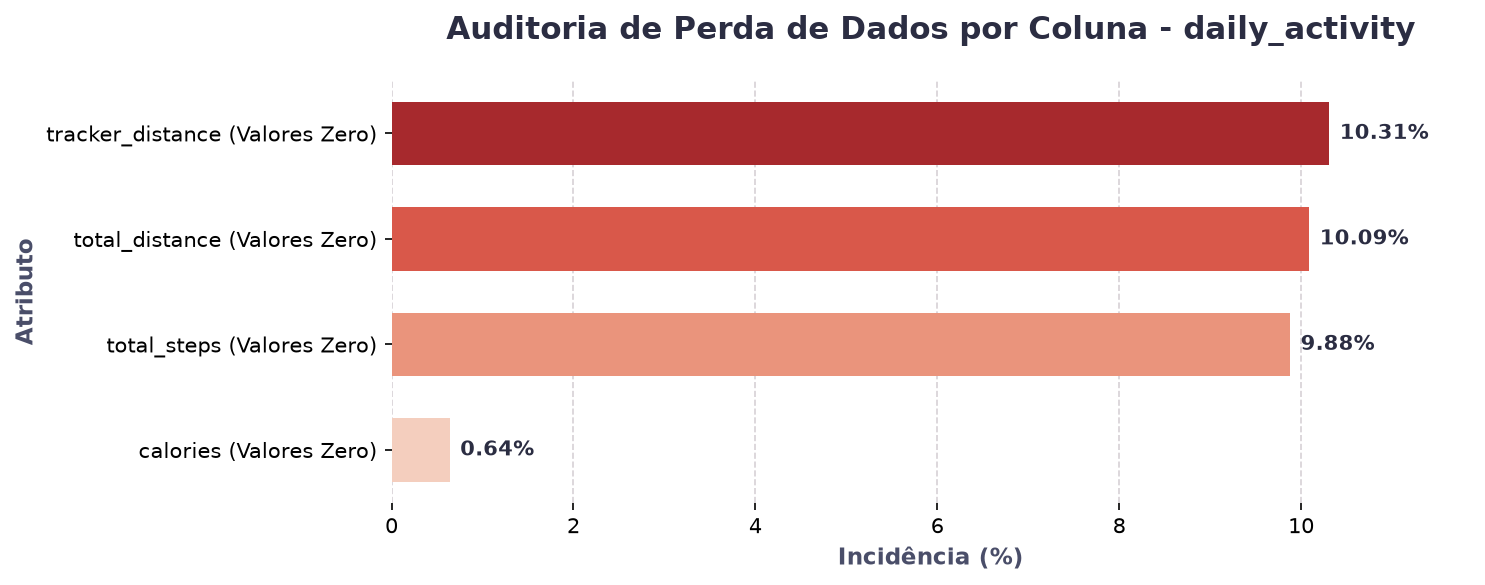

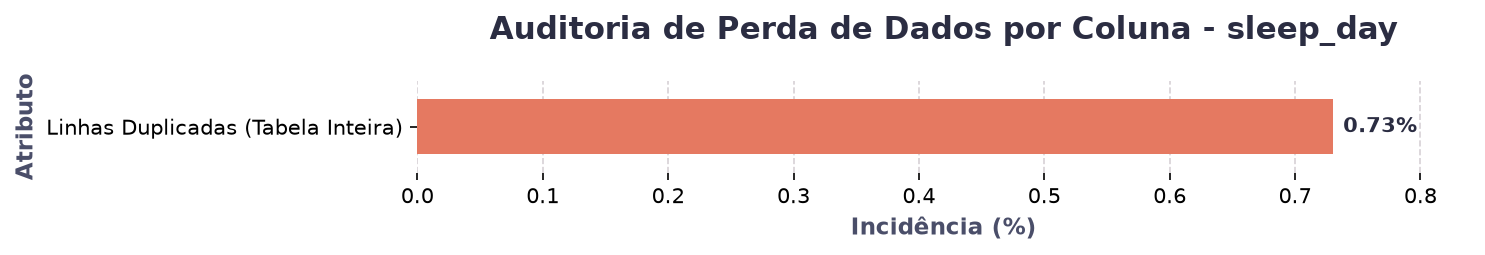

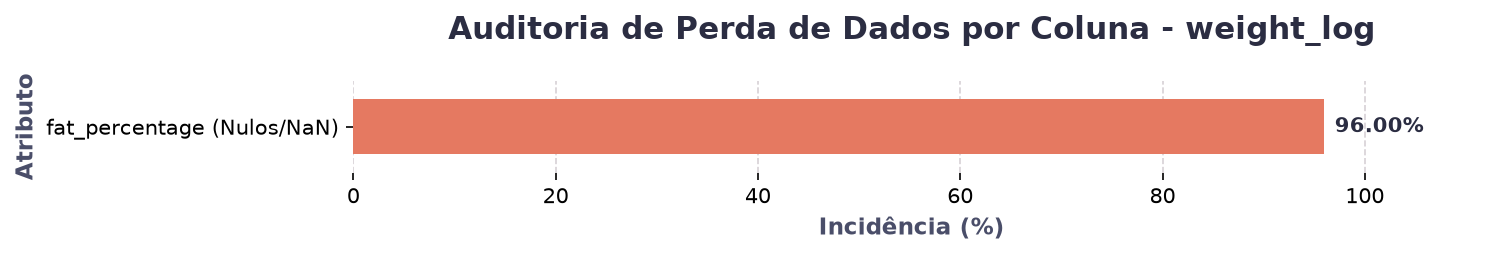



[hourly_steps] Nenhum valor nulo ou zero encontrado.




In [575]:
# Roda o diagnóstico filtrando as colunas normais

dfs_missing_data = {}

for df_nome, df in dfs.items():
    df_qa = check_data_quality(df, ignorar_zeros_em=colunas_normais)
    dfs_missing_data[df_nome] = df_qa

    if df_qa.empty:
        print(f"[{df_nome}] Nenhum valor nulo ou zero encontrado.")
    else:
        chart_percentage_missing_data(df_plot=dfs_missing_data[df_nome], nome_dataframe=df_nome)
    print("\n" + "=" * 125 + "\n")

### 6.2 Explorando Anômalias em DataFrames

#### 6.2.1 Checando Registros da Tabela *daily_activity*

In [576]:
# Checando registros de não-uso (valores zero) na tabela daily_activity coluna 'tracker_distance'
dfs['daily_activity'][dfs['daily_activity']['tracker_distance'] <= 0]

,user_id,activity_date,total_steps,total_distance,tracker_distance,logged_activities_distance,very_active_distance,moderately_active_distance,light_active_distance,sedentary_active_distance,very_active_minutes,fairly_active_minutes,lightly_active_minutes,sedentary_minutes,calories,source_folder
30,1503960366,2016-05-12,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,0,Fitabase Data 4.12.16-5.12.16
104,1844505072,2016-04-24,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1347,Fitabase Data 4.12.16-5.12.16
105,1844505072,2016-04-25,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1347,Fitabase Data 4.12.16-5.12.16
106,1844505072,2016-04-26,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1347,Fitabase Data 4.12.16-5.12.16
107,1844505072,2016-04-27,4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,1,1439,1348,Fitabase Data 4.12.16-5.12.16
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1342,8253242879,2016-04-02,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1429,Fitabase Data 3.12.16-4.11.16
1343,8253242879,2016-04-03,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1429,Fitabase Data 3.12.16-4.11.16
1344,8253242879,2016-04-04,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1429,Fitabase Data 3.12.16-4.11.16
1345,8253242879,2016-04-05,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1429,Fitabase Data 3.12.16-4.11.16


In [577]:
# Checando registros de não-uso (valores zero) na tabela daily_activity coluna 'total_distance'
dfs['daily_activity'][dfs['daily_activity']['total_distance'] <= 0]

,user_id,activity_date,total_steps,total_distance,tracker_distance,logged_activities_distance,very_active_distance,moderately_active_distance,light_active_distance,sedentary_active_distance,very_active_minutes,fairly_active_minutes,lightly_active_minutes,sedentary_minutes,calories,source_folder
30,1503960366,2016-05-12,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,0,Fitabase Data 4.12.16-5.12.16
104,1844505072,2016-04-24,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1347,Fitabase Data 4.12.16-5.12.16
105,1844505072,2016-04-25,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1347,Fitabase Data 4.12.16-5.12.16
106,1844505072,2016-04-26,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1347,Fitabase Data 4.12.16-5.12.16
107,1844505072,2016-04-27,4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,1,1439,1348,Fitabase Data 4.12.16-5.12.16
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1342,8253242879,2016-04-02,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1429,Fitabase Data 3.12.16-4.11.16
1343,8253242879,2016-04-03,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1429,Fitabase Data 3.12.16-4.11.16
1344,8253242879,2016-04-04,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1429,Fitabase Data 3.12.16-4.11.16
1345,8253242879,2016-04-05,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1429,Fitabase Data 3.12.16-4.11.16


In [578]:
# Checando registros de não-uso (valores zero) na tabela daily_activity coluna 'total_steps'
dfs['daily_activity'][dfs['daily_activity']['total_steps'] <= 0]

,user_id,activity_date,total_steps,total_distance,tracker_distance,logged_activities_distance,very_active_distance,moderately_active_distance,light_active_distance,sedentary_active_distance,very_active_minutes,fairly_active_minutes,lightly_active_minutes,sedentary_minutes,calories,source_folder
30,1503960366,2016-05-12,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,0,Fitabase Data 4.12.16-5.12.16
104,1844505072,2016-04-24,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1347,Fitabase Data 4.12.16-5.12.16
105,1844505072,2016-04-25,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1347,Fitabase Data 4.12.16-5.12.16
106,1844505072,2016-04-26,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1347,Fitabase Data 4.12.16-5.12.16
112,1844505072,2016-05-02,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1348,Fitabase Data 4.12.16-5.12.16
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1342,8253242879,2016-04-02,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1429,Fitabase Data 3.12.16-4.11.16
1343,8253242879,2016-04-03,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1429,Fitabase Data 3.12.16-4.11.16
1344,8253242879,2016-04-04,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1429,Fitabase Data 3.12.16-4.11.16
1345,8253242879,2016-04-05,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,1429,Fitabase Data 3.12.16-4.11.16


In [579]:
# Checando registros de não-uso (valores zero) na tabela daily_activity coluna 'calories'
dfs['daily_activity'][dfs['daily_activity']['calories'] <= 0]

,user_id,activity_date,total_steps,total_distance,tracker_distance,logged_activities_distance,very_active_distance,moderately_active_distance,light_active_distance,sedentary_active_distance,very_active_minutes,fairly_active_minutes,lightly_active_minutes,sedentary_minutes,calories,source_folder
30,1503960366,2016-05-12,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,0,Fitabase Data 4.12.16-5.12.16
653,6290855005,2016-05-10,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,0,Fitabase Data 4.12.16-5.12.16
817,8253242879,2016-04-30,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,0,Fitabase Data 4.12.16-5.12.16
879,8583815059,2016-05-12,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,0,Fitabase Data 4.12.16-5.12.16
1074,2873212765,2016-04-12,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,0,Fitabase Data 3.12.16-4.11.16
1180,4319703577,2016-04-09,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,0,Fitabase Data 3.12.16-4.11.16
1230,4702921684,2016-04-12,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,0,Fitabase Data 3.12.16-4.11.16
1263,6117666160,2016-04-10,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,0,Fitabase Data 3.12.16-4.11.16
1352,8253242879,2016-04-12,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,1440,0,Fitabase Data 3.12.16-4.11.16


#### 6.2.2 Checando Registros da Tabela *sleep_day*

In [580]:
# Conferindo registros duplicados da tabela sleep_day
total_duplicados = dfs['sleep_day'].duplicated().sum()
print(f"Total de registros duplicados em 'sleep_day': {total_duplicados}\n")

# Se houver duplicados, exibe quais são as linhas exatas (mostrando todas as ocorrências)
if total_duplicados > 0:
    display(dfs['sleep_day'][dfs['sleep_day'].duplicated(keep=False)].sort_values(by='user_id'))

Total de registros duplicados em 'sleep_day': 3



,user_id,sleep_date,total_sleep_records,total_minutes_asleep,total_time_in_bed,source_folder
160,4388161847,2016-05-05,1,471,495,Fitabase Data 4.12.16-5.12.16
161,4388161847,2016-05-05,1,471,495,Fitabase Data 4.12.16-5.12.16
222,4702921684,2016-05-07,1,520,543,Fitabase Data 4.12.16-5.12.16
223,4702921684,2016-05-07,1,520,543,Fitabase Data 4.12.16-5.12.16
379,8378563200,2016-04-25,1,388,402,Fitabase Data 4.12.16-5.12.16
380,8378563200,2016-04-25,1,388,402,Fitabase Data 4.12.16-5.12.16


#### 6.2.3 Checando Registros da Tabela *weight_log*

In [581]:
# Checando registros ausentes na tabela weight_log coluna 'fat_percentage'
dfs['weight_log'][dfs['weight_log']['fat_percentage'].isnull()].head(10)

,user_id,weight_date,weight_kg,weight_pounds,fat_percentage,bmi,is_manual_report,log_id,source_folder
1,1503960366,2016-05-03 23:59:59,52.599998,115.963147,NaN,22.650000,True,1462319999000,Fitabase Data 4.12.16-5.12.16
2,1927972279,2016-04-13 01:08:52,133.500000,294.317120,NaN,47.540001,False,1460509732000,Fitabase Data 4.12.16-5.12.16
3,2873212765,2016-04-21 23:59:59,56.700001,125.002104,NaN,21.450001,True,1461283199000,Fitabase Data 4.12.16-5.12.16
4,2873212765,2016-05-12 23:59:59,57.299999,126.324875,NaN,21.690001,True,1463097599000,Fitabase Data 4.12.16-5.12.16
6,4319703577,2016-05-04 23:59:59,72.300003,159.394222,NaN,27.379999,True,1462406399000,Fitabase Data 4.12.16-5.12.16
7,4558609924,2016-04-18 23:59:59,69.699997,153.662190,NaN,27.250000,True,1461023999000,Fitabase Data 4.12.16-5.12.16
8,4558609924,2016-04-25 23:59:59,70.300003,154.984977,NaN,27.459999,True,1461628799000,Fitabase Data 4.12.16-5.12.16
9,4558609924,2016-05-01 23:59:59,69.900002,154.103125,NaN,27.320000,True,1462147199000,Fitabase Data 4.12.16-5.12.16
10,4558609924,2016-05-02 23:59:59,69.199997,152.559879,NaN,27.040001,True,1462233599000,Fitabase Data 4.12.16-5.12.16
11,4558609924,2016-05-09 23:59:59,69.099998,152.339420,NaN,27.000000,True,1462838399000,Fitabase Data 4.12.16-5.12.16


### Limpeza de Dados e Aplicação de Regras de Negócio (Wearables)

Com base nos resultados gerados pelo nosso módulo de auditoria de qualidade (`data_quality.py`), identificamos dois cenários distintos que exigem tratamento na **Camada Silver** para evitar distorções matemáticas nas análises futuras:

1. **Remoção de Coluna Irrecuperável (`weight_log`):**
   * **Diagnóstico:** A coluna `fat_percentage` apresenta **96% de valores nulos (NaN)**. Isso indica uma baixíssima adoção dos usuários em registrar esse dado manualmente ou limitações do hardware da balança inteligente.
   * **Ação:** A coluna será **eliminada**. Tentar preencher (imputar) um volume tão alto de dados faltantes invalidaria qualquer análise estatística de composição corporal.

2. **Remoção de "Dias Fantasmas" (`daily_activity`):**
   * **Diagnóstico:** Identificamos aproximadamente 10% de registros com valor `0` nas colunas `total_steps`, `total_distance`, `tracker_distance` e `0.64%` em `calories`. Como é fisiologicamente impossível um corpo humano gastar 0 calorias em 24 horas, esses registros não representam sedentarismo, mas sim dias em que o usuário **não utilizou o dispositivo** (aparelho desligado, na gaveta ou carregando).
   * **Ação:** Removeremos as **linhas** que contenham zeros nessas variáveis simultaneamente. Manter esses "dias sem uso" puxaria a média geral de atividade e gasto calórico dos usuários para baixo de forma artificial. 

<br>


### 6.3 Tratamento de Dados Ausentes e Anômalos

#### 6.3.1 Tratando Tabela *weight_log* (Valores Ausentes)

In [582]:
# Tratamento da tabela 'weight_log' (Remover a coluna fat_percentage)
print(f"Tamanho de weight_log antes: {dfs['weight_log'].shape}")

if 'fat_percentage' in dfs['weight_log'].columns:
    dfs['weight_log'] = dfs['weight_log'].drop(columns=['fat_percentage'])

print(f"Tamanho de weight_log depois: {dfs['weight_log'].shape}\n")

Tamanho de weight_log antes: (100, 9)
Tamanho de weight_log depois: (100, 8)



#### 6.3.2 Tratando Tabela *daily_activity* (Valores Anômalos - Zeros)

In [583]:
# Tratamento da tabela 'daily_activity' (Remover registros de não-uso)
print(f"Tamanho de daily_activity antes: {dfs['daily_activity'].shape}")

# Filtra a tabela mantendo apenas os dias onde o rastreador registrou alguma distância, 
# o que limpa automaticamente os zeros das colunas dependentes (passos e calorias)
dfs['daily_activity'] = dfs['daily_activity'][dfs['daily_activity']['tracker_distance'] > 0]

print(f"Tamanho de daily_activity depois: {dfs['daily_activity'].shape}")

Tamanho de daily_activity antes: (1397, 16)
Tamanho de daily_activity depois: (1253, 16)


#### 6.3.3 Tratando Tabela *sleep_day* (Valores Anômalos - Duplicados)

In [584]:
# Tratamento da tabela 'sleep_day' (Remover registros duplicados)
print(f"Tamanho de sleep_day antes: {dfs['sleep_day'].shape}")

# Removendo os registros duplicados e atualizando o DataFrame
dfs['sleep_day'] = dfs['sleep_day'].drop_duplicates()

print(f"Tamanho de sleep_day após a remoção: {dfs['sleep_day'].shape}")

Tamanho de sleep_day antes: (413, 6)
Tamanho de sleep_day após a remoção: (410, 6)


### 6.3 Checando DataFrames pós tratamento 

In [585]:
# Roda o diagnóstico filtrando as colunas normais

dfs_missing_data = {}

for df_nome, df in dfs.items():
    df_qa = check_data_quality(df, ignorar_zeros_em=colunas_normais)
    dfs_missing_data[df_nome] = df_qa

    if df_qa.empty:
        print(f"[{df_nome}] Nenhum valor nulo ou zero encontrado.")
    else:
        chart_percentage_missing_data(df_plot=dfs_missing_data[df_nome], nome_dataframe=df_nome)
    print("\n" + "=" * 100 + "\n")

[daily_activity] Nenhum valor nulo ou zero encontrado.


[sleep_day] Nenhum valor nulo ou zero encontrado.


[weight_log] Nenhum valor nulo ou zero encontrado.


[hourly_steps] Nenhum valor nulo ou zero encontrado.




---

## 7. Criação de Novas Variáveis

### 7.1 Tabela *daily_activity*

In [586]:
# Observando a estrutura do DataFrame daily_activity após o tratamento
dfs['daily_activity'].info()

<class 'pandas.DataFrame'>
Index: 1253 entries, 0 to 1396
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   user_id                     1253 non-null   int64         
 1   activity_date               1253 non-null   datetime64[us]
 2   total_steps                 1253 non-null   int64         
 3   total_distance              1253 non-null   float64       
 4   tracker_distance            1253 non-null   float64       
 5   logged_activities_distance  1253 non-null   float64       
 6   very_active_distance        1253 non-null   float64       
 7   moderately_active_distance  1253 non-null   float64       
 8   light_active_distance       1253 non-null   float64       
 9   sedentary_active_distance   1253 non-null   float64       
 10  very_active_minutes         1253 non-null   int64         
 11  fairly_active_minutes       1253 non-null   int64         
 12  lightly_

In [587]:
# Extração do nome do dia (Monday, Tuesday, etc.) a partir da data
dfs['daily_activity']['day_of_week'] = dfs['daily_activity']['activity_date'].dt.day_name()

In [588]:
# Confirmando a extração do nome do dia da semana
dfs['daily_activity'][['activity_date', 'day_of_week']].head(10)

,activity_date,day_of_week
0,2016-04-12,Tuesday
1,2016-04-13,Wednesday
2,2016-04-14,Thursday
3,2016-04-15,Friday
4,2016-04-16,Saturday
5,2016-04-17,Sunday
6,2016-04-18,Monday
7,2016-04-19,Tuesday
8,2016-04-20,Wednesday
9,2016-04-21,Thursday


In [589]:
# Soma das colunas very_active, fairly_active e lightly_active  
dfs['daily_activity']['total_active_minutes'] = (
    dfs['daily_activity']['very_active_minutes'] +
    dfs['daily_activity']['fairly_active_minutes'] +
    dfs['daily_activity']['lightly_active_minutes']
)

In [590]:
# Confirmando a criação da nova coluna
dfs['daily_activity'][[
    'very_active_minutes', 
    'fairly_active_minutes', 
    'lightly_active_minutes', 
    'total_active_minutes'
]].head(10)

,very_active_minutes,fairly_active_minutes,lightly_active_minutes,total_active_minutes
0,25,13,328,366
1,21,19,217,257
2,30,11,181,222
3,29,34,209,272
4,36,10,221,267
5,38,20,164,222
6,42,16,233,291
7,50,31,264,345
8,28,12,205,245
9,19,8,211,238


#### Novas Variáveis da Tabela *daily_activity*

* **`day_of_week` (Day of Week):** Extraído a partir da data. 
  * *Justificativa:* Fundamental para cruzar dados temporais e responder a perguntas estratégicas, como: "Os usuários são mais ativos nos finais de semana ou durante a semana de trabalho?".
* **`total_active_minutes`:** A soma das categorias de minutos ativos (`very` + `fairly` + `lightly`). 
  * *Justificativa:* Cria uma métrica unificada de movimento diário, facilitando o contraste direto contra a variável `sedentary_minutes` em gráficos e agregações.


#### 7.2 Tabela *sleep_day*

In [591]:
# Observando a estrutura do DataFrame sleep_day após o tratamento
dfs['sleep_day'].info()

<class 'pandas.DataFrame'>
Index: 410 entries, 0 to 412
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   user_id               410 non-null    int64         
 1   sleep_date            410 non-null    datetime64[us]
 2   total_sleep_records   410 non-null    int64         
 3   total_minutes_asleep  410 non-null    int64         
 4   total_time_in_bed     410 non-null    int64         
 5   source_folder         410 non-null    str           
dtypes: datetime64[us](1), int64(4), str(1)
memory usage: 34.1 KB


In [592]:
# Extração do tempo acordado na cama (em minutos) a partir das colunas TotalTimeInBed e TotalMinutesAsleep
dfs['sleep_day']['minutes_awake_in_bed'] = (
    dfs['sleep_day']['total_time_in_bed'] - 
    dfs['sleep_day']['total_minutes_asleep']
)

In [593]:
# Confirmando a criação da nova coluna
dfs['sleep_day'][[
    'total_time_in_bed',
    'total_minutes_asleep',
    'minutes_awake_in_bed'
]].head(10)

,total_time_in_bed,total_minutes_asleep,minutes_awake_in_bed
0,346,327,19
1,407,384,23
2,442,412,30
3,367,340,27
4,712,700,12
5,320,304,16
6,377,360,17
7,364,325,39
8,384,361,23
9,449,430,19


#### Novas Variáveis da Tabela *sleep_day*

* **`minutes_awake_in_bed`:** Calculado pela diferença entre o tempo total na cama (`total_time_in_bed`) e o tempo efetivamente dormindo (`total_minutes_asleep`). 
  * *Justificativa:* Serve como um excelente indicador biológico da **qualidade do sono**. Valores altos constantes podem indicar dificuldade para adormecer (insônia) ou uso excessivo do celular deitado, oferecendo um gancho perfeito para o marketing de bem-estar da Bellabeat.


#### 7.3 Tabela *hourly_steps*

In [594]:
# Observando a estrutura do DataFrame hourly_steps após o tratamento
dfs['hourly_steps'].info()

<class 'pandas.DataFrame'>
RangeIndex: 46183 entries, 0 to 46182
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   user_id        46183 non-null  int64         
 1   activity_hour  46183 non-null  datetime64[us]
 2   step_total     46183 non-null  int64         
 3   source_folder  46183 non-null  str           
dtypes: datetime64[us](1), int64(2), str(1)
memory usage: 2.7 MB


In [595]:
# Extração da hora do dia (0-23) a partir da coluna activity_hour
dfs['hourly_steps']['hour_of_day'] = dfs['hourly_steps']['activity_hour'].dt.hour

In [596]:
# Confirmando a criação da nova coluna
dfs['hourly_steps'][[
    'activity_hour',
    'hour_of_day'
]].head(24)

,activity_hour,hour_of_day
0,2016-04-12 00:00:00,0
1,2016-04-12 01:00:00,1
2,2016-04-12 02:00:00,2
3,2016-04-12 03:00:00,3
4,2016-04-12 04:00:00,4
5,2016-04-12 05:00:00,5
6,2016-04-12 06:00:00,6
7,2016-04-12 07:00:00,7
8,2016-04-12 08:00:00,8
9,2016-04-12 09:00:00,9


In [597]:
# Dicionario de turnos do dia
turnos = {
    'Madrugada': (0, 5),
    'Manhã': (6, 11),
    'Tarde': (12, 17),
    'Noite': (18, 23)
}

# Criando uma função para mapear a hora do dia para o turno correspondente
def mapear_turno(hora):
    for turno, (inicio, fim) in turnos.items():
        if inicio <= hora <= fim:
            return turno
    return None  # Caso a hora não se encaixe em nenhum turno

In [598]:
# Criando nova coluna 'day_period' no DataFrame hourly_steps usando a função mapear_turno
dfs['hourly_steps']['day_period'] = dfs['hourly_steps']['hour_of_day'].apply(mapear_turno)

In [599]:
# Confirmando a criação da nova coluna
dfs['hourly_steps'][[
    'activity_hour',
    'hour_of_day',
    'day_period'
]].head(24)

,activity_hour,hour_of_day,day_period
0,2016-04-12 00:00:00,0,Madrugada
1,2016-04-12 01:00:00,1,Madrugada
2,2016-04-12 02:00:00,2,Madrugada
3,2016-04-12 03:00:00,3,Madrugada
4,2016-04-12 04:00:00,4,Madrugada
5,2016-04-12 05:00:00,5,Madrugada
6,2016-04-12 06:00:00,6,Manhã
7,2016-04-12 07:00:00,7,Manhã
8,2016-04-12 08:00:00,8,Manhã
9,2016-04-12 09:00:00,9,Manhã


#### Novas Variáveis da Tabela *hourly_steps*


* **`hour_of_day` e `day_period`:** Extração da hora exata (0-23) e categorização em blocos (Madrugada, Manhã, Tarde, Noite).
  * *Justificativa:* Como a coluna original de data e hora é contínua, é impossível agregar a média de passos por horário sem antes isolar a hora. Isso nos permitirá descobrir os picos diários de atividade, direcionando o envio de notificações de motivação no aplicativo exatamente para os horários em que os usuários estão mais dispostos a se exercitar.

---

## 8. Identificação e Tratamento de Outliers 

### 8.1 Tabela *daily_activity*

In [600]:
# Observando a estrutura do DataFrame daily_activity após o tratamento
pd.DataFrame({'Colunas' : dfs['daily_activity'].columns})

,Colunas
0,user_id
1,activity_date
2,total_steps
3,total_distance
4,tracker_distance
5,logged_activities_distance
6,very_active_distance
7,moderately_active_distance
8,light_active_distance
9,sedentary_active_distance


In [601]:
# Diagnostico de outliers na tabela daily_activity, ignorando a coluna user_id
df_diagnostico = batch_outlier_diagnosis(dfs['daily_activity'], colunas_ignorar=['user_id'])

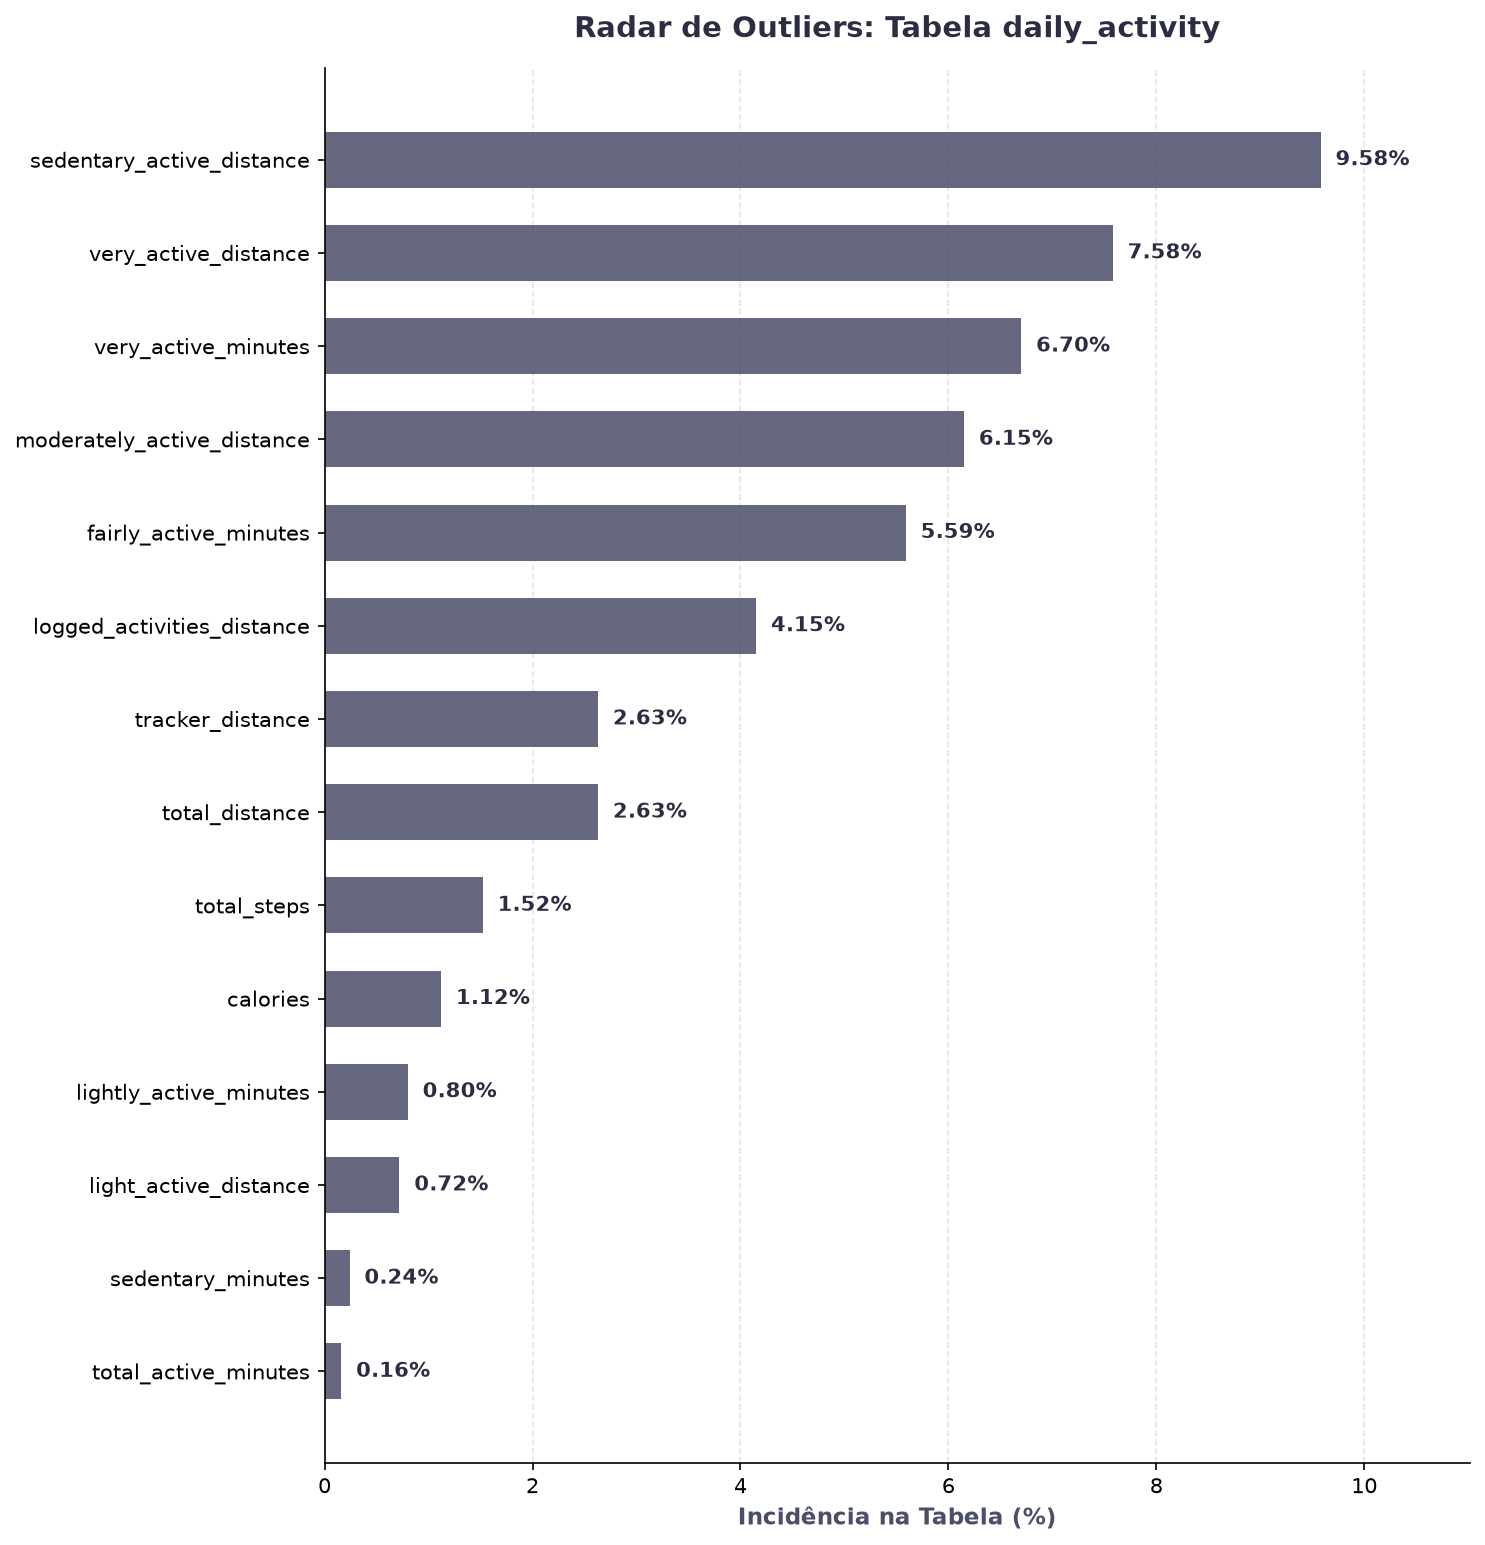

In [602]:
radar_chart_outliers(
    df_diagnostico,
    titulo="Radar de Outliers: Tabela daily_activity"
)

#### 8.1.1 Coluna `total_steps`

In [603]:
# Calcula os limites chamando o novo módulo (ignorando o limite inferior com "_")
_, limite_sup = calculate_limits_iqr(dfs['daily_activity'], 'total_steps')

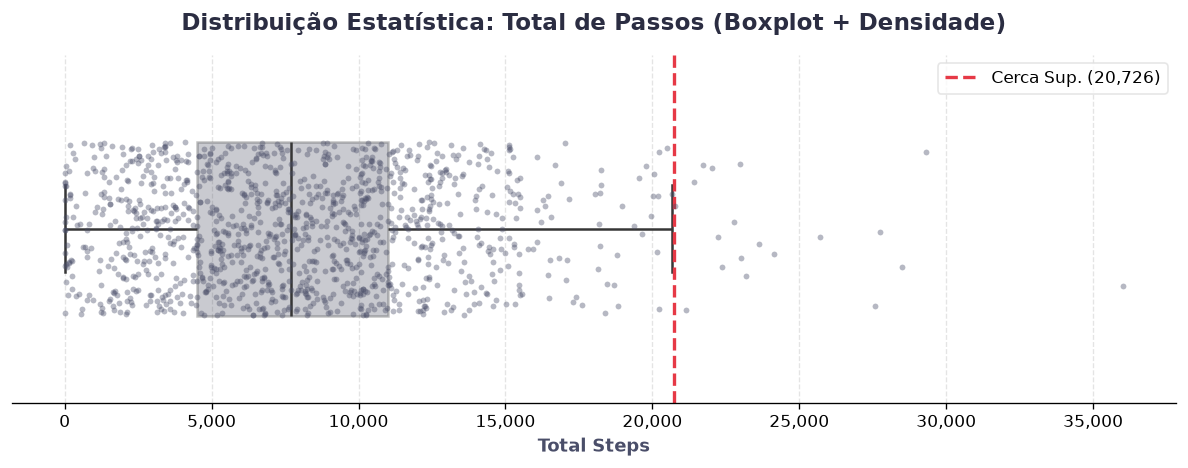

In [604]:
# Gera o Boxplot detalhado com a fronteira da cerca superior
outlier_plot(
    df_plot=dfs['daily_activity'],
    coluna='total_steps',
    cerca_superior=limite_sup,
    titulo="Distribuição Estatística: Total de Passos (Boxplot + Densidade)"
)

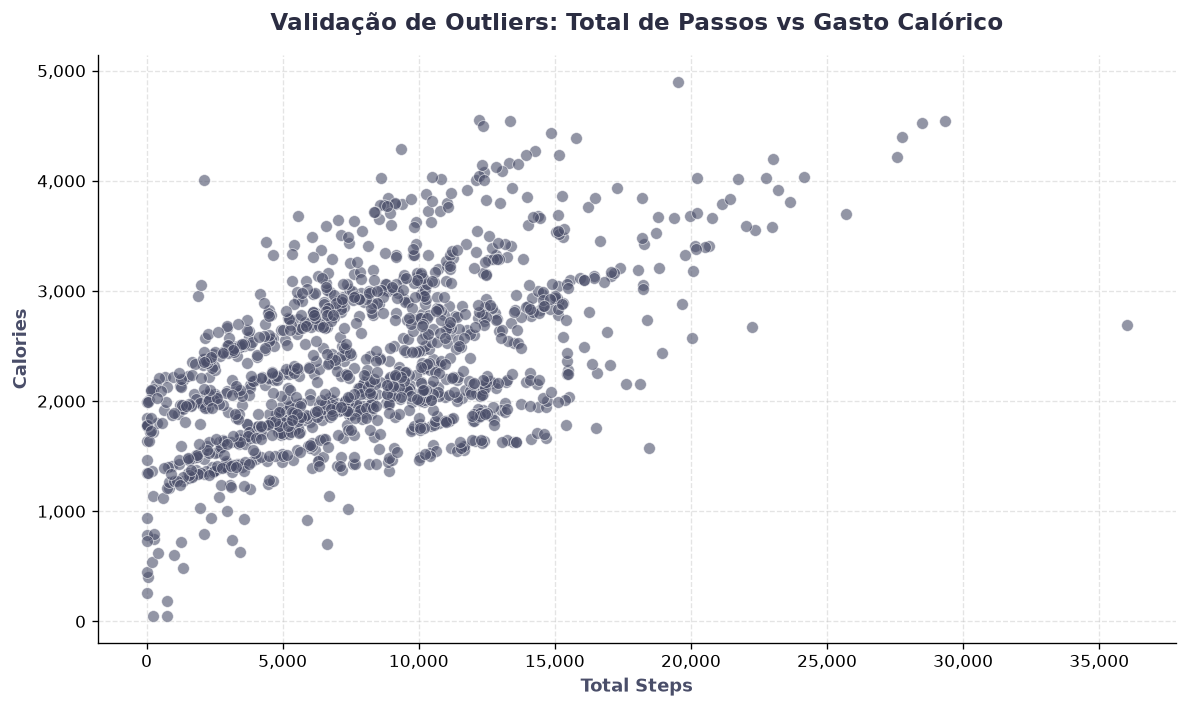

In [605]:
validation_scatter_plot(
    df=dfs['daily_activity'],
    coluna_x='total_steps',
    coluna_y='calories',
    titulo="Validação de Outliers: Total de Passos vs Gasto Calórico"
)

In [606]:
# Lista de colunas para análise detalhada
colunas_analise_steps=[
    'user_id', 
    'activity_date', 
    'total_steps', 
    'total_distance', 
    'calories', 
    'very_active_minutes'
]

# Executa a função unificada e totalmente dinâmica
outliers_summary(
    df=dfs['daily_activity'],
    coluna='total_steps',
    limite_sup=limite_sup,
    colunas_analise = colunas_analise_steps,
    titulo="Top 10 maiores registros de Total Steps"
)

   RESUMO DE OUTLIERS: TOTAL_STEPS 
• Cerca Superior (IQR): 20,726.50
• Quantidade de Outliers: 19 de 1253 registros
• Impacto na Tabela: 1.52%

• Valor mínimo entre outliers: 20,779.00
• Valor máximo entre outliers: 36,019.00

Distribuição de outliers por Utilizador:


,Id_Usuario,dias_com_outlier
0,8877689391,12
1,8053475328,4
2,1624580081,1
3,2347167796,1
4,4388161847,1



Top 10 maiores registros de Total Steps:


,user_id,total_steps,activity_date,total_distance,calories,very_active_minutes
50,1624580081,36019,2016-05-01,28.030001,2690,186
913,8877689391,29326,2016-04-16,25.290001,4547,94
1394,8877689391,28497,2016-04-10,27.530001,4526,128
927,8877689391,27745,2016-04-30,26.719999,4398,124
1386,8877689391,27572,2016-04-02,23.389999,4220,116
1331,8053475328,25701,2016-04-03,20.139999,3697,165
1390,8877689391,24136,2016-04-06,20.910000,4039,87
924,8877689391,23629,2016-04-27,20.650000,3808,93
909,8877689391,23186,2016-04-12,20.400000,3921,85
1392,8877689391,23014,2016-04-08,20.389999,4196,70


#### 8.1.2 Coluna `sedentary_active_distance`

In [607]:
# Calcula os limites chamando o novo módulo (ignorando o limite inferior com "_")
limite_inf, limite_sup = calculate_limits_iqr(dfs['daily_activity'], 'sedentary_active_distance')

In [608]:
# Lista de colunas para análise detalhada
colunas_analise_sedentary = [
    'user_id', 
    'activity_date', 
    'sedentary_active_distance',
    'light_active_distance',
    'moderately_active_distance',
    'very_active_distance',
    'sedentary_minutes',
    'calories'
]

# Executa a função unificada e totalmente dinâmica
outliers_summary(
    df=dfs['daily_activity'],
    coluna='total_steps',
    limite_sup=limite_sup,
    limite_inf=limite_inf,
    colunas_analise = colunas_analise_sedentary,
    titulo="Top 10 maiores registros de Total Steps"
)

   RESUMO DE OUTLIERS: TOTAL_STEPS 
• Cerca Superior (IQR): 0.00
• Cerca Inferior (IQR): 0.00
• Quantidade de Outliers: 1253 de 1253 registros
• Impacto na Tabela: 100.00%

• Valor mínimo entre outliers: 7.00
• Valor máximo entre outliers: 36,019.00

Distribuição de outliers por Utilizador:


,Id_Usuario,dias_com_outlier
0,1624580081,50
1,1503960366,49
2,4020332650,49
3,4445114986,46
4,6962181067,45
5,4702921684,44
6,2022484408,43
7,2026352035,43
8,4558609924,43
9,5553957443,43



Top 10 maiores registros de Total Steps:


,user_id,total_steps,activity_date,sedentary_active_distance,light_active_distance,moderately_active_distance,very_active_distance,sedentary_minutes,calories
50,1624580081,36019,2016-05-01,0.02,1.91,4.19,21.92,1020,2690
913,8877689391,29326,2016-04-16,0.00,10.71,1.21,13.24,888,4547
1394,8877689391,28497,2016-04-10,0.00,4.46,1.12,21.92,1055,4526
927,8877689391,27745,2016-04-30,0.00,4.93,0.08,21.66,1089,4398
1386,8877689391,27572,2016-04-02,0.01,7.34,1.21,14.72,1040,4220
1331,8053475328,25701,2016-04-03,0.00,1.69,1.63,16.82,1142,3697
1390,8877689391,24136,2016-04-06,0.00,8.08,0.54,12.22,1019,4039
924,8877689391,23629,2016-04-27,0.00,7.10,0.44,13.07,1104,3808
909,8877689391,23186,2016-04-12,0.00,7.82,0.34,12.22,1036,3921
1392,8877689391,23014,2016-04-08,0.00,8.62,0.63,11.10,982,4196


#### 8.1.3 Coluna `logged_activities_distance`

In [609]:
# Calcula os limites chamando o novo módulo (ignorando o limite inferior com "_")
limite_inf, limite_sup = calculate_limits_iqr(dfs['daily_activity'], 'logged_activities_distance')

In [610]:
# Lista de colunas para análise detalhada
colunas_analise_logged=[
    'activity_date', 
    'total_steps', 
    'calories', 
    'sedentary_minutes'
]


# Executa a função unificada e totalmente dinâmica
outliers_summary(
    df=dfs['daily_activity'],
    coluna='logged_activities_distance',
    limite_sup=limite_sup,
    limite_inf=limite_inf,
    colunas_analise=colunas_analise_logged,
    titulo="Top 10 maiores registros de Logged Activities Distance"
)

   RESUMO DE OUTLIERS: LOGGED_ACTIVITIES_DISTANCE 
• Cerca Superior (IQR): 0.00
• Cerca Inferior (IQR): 0.00
• Quantidade de Outliers: 52 de 1253 registros
• Impacto na Tabela: 4.15%

• Valor mínimo entre outliers: 0.06
• Valor máximo entre outliers: 6.73

Distribuição de outliers por Utilizador:


,Id_Usuario,dias_com_outlier
0,8378563200,23
1,7007744171,19
2,6962181067,7
3,6775888955,1
4,4057192912,1
5,6391747486,1



Top 10 maiores registros de Logged Activities Distance:


,user_id,logged_activities_distance,activity_date,total_steps,calories,sedentary_minutes
1278,6391747486,6.727057,2016-04-05,9766,2442,1133
1301,6962181067,5.456864,2016-04-08,14400,2188,697
1309,7007744171,5.189850,2016-04-04,15266,2886,1057
718,7007744171,4.942142,2016-04-19,14194,2812,1066
717,7007744171,4.930550,2016-04-18,14816,2832,1077
719,7007744171,4.924841,2016-04-20,15566,3096,1000
732,7007744171,4.912368,2016-05-03,14510,2976,1021
728,7007744171,4.911146,2016-04-29,20067,3180,961
1306,7007744171,4.901283,2016-04-01,11680,2573,1139
726,7007744171,4.885605,2016-04-27,13541,2830,1041


###  Validação de Outliers Tabela *daily_activity*

#### Colunas Analisadas em Detalhe
* **`total_steps` (Passos Totais):** Métrica core de engajamento; avaliada para distinguir falhas de sincronização de app da performance real de utilizadores de alta intensidade.
* **`sedentary_active_distance` (Distância Ativa Sedentária):** Investigada devido à contradição lógica do nome e alta incidência no radar (9,58%); concluiu-se que a cerca superior era zero e capta apenas micro-movimentos residuais em repouso.
* **`very_active_minutes` / `very_active_distance` (Atividade Intensa):** Analisadas para mapear com segurança o comportamento de treino dos power users.

#### Por que Analisamos Estas Colunas?
A priorização focou em separar **ruídos técnicos** (verificando se havia bugs de hardware/sensor) de **variabilidades comportamentais**, garantindo que métricas vitais para a proposta de valor da Bellabeat não estivessem corrompidas.

#### Decisão: Manutenção Integral dos Outliers
Nenhum registo extremo será removido da Camada Silver pelos seguintes fundamentos:
* **Validade Biológica (*Sanity Check*):** Os valores elevados acompanham gasto calórico e distâncias perfeitamente proporcionais, respeitando as leis físicas.
* **Preservação de *Power Users*:** Apagar estes dados eliminaria o perfil das utilizadoras mais ativas (atletas/maratonistas), essencial para estratégias de marketing e recursos *premium*.
* **Inexpressividade de Erros:** Os desvios em métricas secundárias são residuais e não afetam as grandes agregações analíticas.
* **Mitigação de Viés:** Manter os dados preserva a distribuição comportamental real da população monitorada, evitando distorções na Análise Exploratória (EDA).

### 8.2 Tabela *sleepDay*

In [611]:
# Observando a estrutura do DataFrame sleep_day após o tratamento
pd.DataFrame({'Colunas' : dfs['sleep_day'].columns})

,Colunas
0,user_id
1,sleep_date
2,total_sleep_records
3,total_minutes_asleep
4,total_time_in_bed
5,source_folder
6,minutes_awake_in_bed


In [612]:
# Diagnostico de outliers na tabela sleep_day, ignorando a coluna user_id
df_diagnostico = batch_outlier_diagnosis(dfs['sleep_day'], colunas_ignorar=['user_id'])

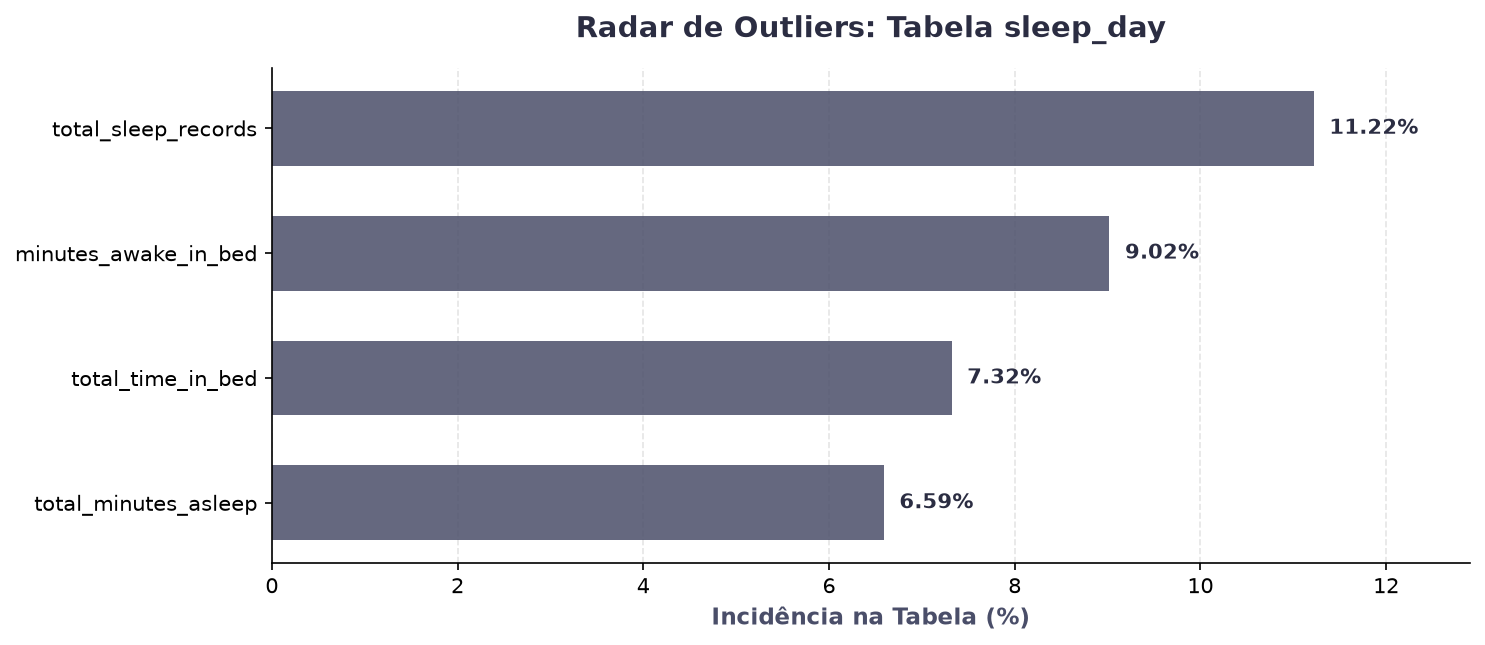

In [613]:
radar_chart_outliers(
    df_diagnostico,
    titulo="Radar de Outliers: Tabela sleep_day"
)

#### 8.2.1 Coluna `total_steps_records`

In [614]:
# Calcula os limites chamando o novo módulo (ignorando o limite inferior com "_")
limite_inf, limite_sup = calculate_limits_iqr(dfs['sleep_day'], 'total_sleep_records')

In [615]:
# Executa a função unificada e totalmente dinâmica
outliers_summary(
    df=dfs['sleep_day'],
    coluna='total_sleep_records',
    limite_sup=limite_sup,
    limite_inf=limite_inf,
    colunas_analise=dfs['sleep_day'].columns.tolist(),
    titulo="Top 10 maiores registros de Total Sleep Records"
)

   RESUMO DE OUTLIERS: TOTAL_SLEEP_RECORDS 
• Cerca Superior (IQR): 1.00
• Cerca Inferior (IQR): 1.00
• Quantidade de Outliers: 46 de 410 registros
• Impacto na Tabela: 11.22%

• Valor mínimo entre outliers: 2.00
• Valor máximo entre outliers: 3.00

Distribuição de outliers por Utilizador:


,Id_Usuario,dias_com_outlier
0,4445114986,11
1,5553957443,7
2,4388161847,6
3,3977333714,4
4,6117666160,4
5,8378563200,4
6,1503960366,2
7,1927972279,2
8,4702921684,2
9,6962181067,2



Top 10 maiores registros de Total Sleep Records:


,user_id,total_sleep_records,sleep_date,total_minutes_asleep,total_time_in_bed,source_folder,minutes_awake_in_bed
32,1927972279,3,2016-04-12,750,775,Fitabase Data 4.12.16-5.12.16,25
152,4388161847,3,2016-04-24,552,595,Fitabase Data 4.12.16-5.12.16,43
307,6962181067,3,2016-04-13,630,679,Fitabase Data 4.12.16-5.12.16,49
3,1503960366,2,2016-04-16,340,367,Fitabase Data 4.12.16-5.12.16,27
82,3977333714,2,2016-04-13,295,456,Fitabase Data 4.12.16-5.12.16,161
34,1927972279,2,2016-04-15,475,499,Fitabase Data 4.12.16-5.12.16,24
87,3977333714,2,2016-04-18,412,522,Fitabase Data 4.12.16-5.12.16,110
89,3977333714,2,2016-04-20,152,305,Fitabase Data 4.12.16-5.12.16,153
121,4319703577,2,2016-04-19,461,498,Fitabase Data 4.12.16-5.12.16,37
107,3977333714,2,2016-05-08,259,456,Fitabase Data 4.12.16-5.12.16,197


#### 8.2.2 Coluna `minutes_awake_in_bed`

In [616]:
# Calcula os limites para minutes_awake_in_bed
limite_inf, limite_sup = calculate_limits_iqr(dfs['sleep_day'], 'minutes_awake_in_bed')

In [617]:
# Executa a função unificada de sumário tabular
outliers_summary(
    df=dfs['sleep_day'],
    coluna='minutes_awake_in_bed',
    limite_sup=limite_sup,
    limite_inf=limite_inf,
    colunas_analise=dfs['sleep_day'].columns.tolist(),
    titulo="Top 10 maiores registros de Minutes Awake in Bed"
)

   RESUMO DE OUTLIERS: MINUTES_AWAKE_IN_BED 
• Cerca Superior (IQR): 74.50
• Cerca Inferior (IQR): -17.50
• Quantidade de Outliers: 37 de 410 registros
• Impacto na Tabela: 9.02%

• Valor mínimo entre outliers: 76.00
• Valor máximo entre outliers: 371.00

Distribuição de outliers por Utilizador:


,Id_Usuario,dias_com_outlier
0,3977333714,28
1,1844505072,3
2,5553957443,2
3,8378563200,2
4,1644430081,1
5,4445114986,1



Top 10 maiores registros de Minutes Awake in Bed:


,user_id,minutes_awake_in_bed,sleep_date,total_sleep_records,total_minutes_asleep,total_time_in_bed,source_folder
31,1844505072,371,2016-05-01,1,590,961,Fitabase Data 4.12.16-5.12.16
29,1844505072,317,2016-04-15,1,644,961,Fitabase Data 4.12.16-5.12.16
100,3977333714,243,2016-05-01,1,383,626,Fitabase Data 4.12.16-5.12.16
30,1844505072,239,2016-04-30,1,722,961,Fitabase Data 4.12.16-5.12.16
85,3977333714,227,2016-04-16,1,283,510,Fitabase Data 4.12.16-5.12.16
93,3977333714,216,2016-04-24,1,310,526,Fitabase Data 4.12.16-5.12.16
102,3977333714,208,2016-05-03,1,292,500,Fitabase Data 4.12.16-5.12.16
106,3977333714,206,2016-05-07,1,237,443,Fitabase Data 4.12.16-5.12.16
94,3977333714,205,2016-04-25,1,262,467,Fitabase Data 4.12.16-5.12.16
107,3977333714,197,2016-05-08,2,259,456,Fitabase Data 4.12.16-5.12.16


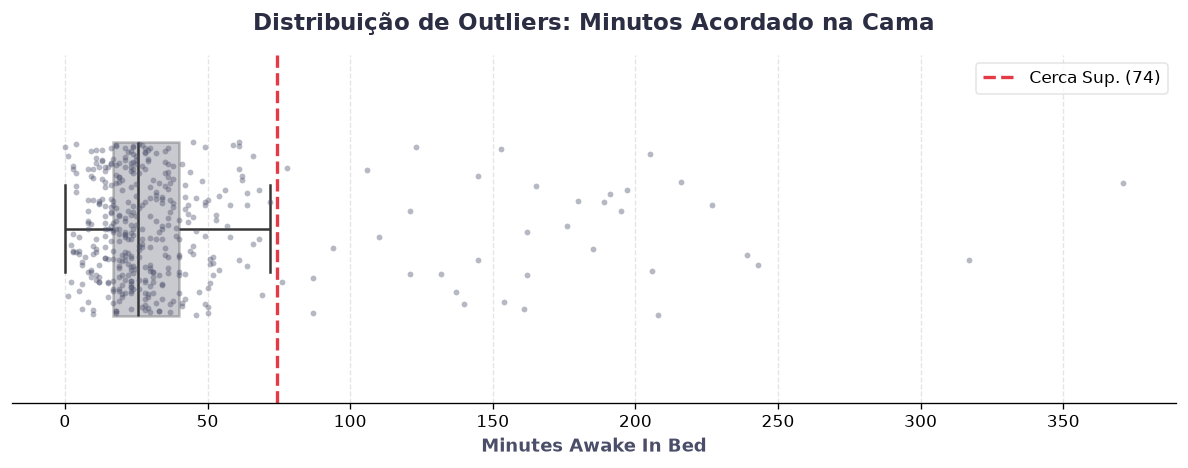

In [618]:
# Gera o Boxplot para inspecionar a distribuição dos minutos acordados
outlier_plot(
    df_plot=dfs['sleep_day'],
    coluna='minutes_awake_in_bed',
    cerca_superior=limite_sup,
    titulo="Distribuição de Outliers: Minutos Acordado na Cama"
)


#### 8.2.3 Coluna `total_time_in_bed`

In [619]:
# Calcula os limites para total_time_in_bed
limite_inf, limite_sup = calculate_limits_iqr(dfs['sleep_day'], 'total_time_in_bed')

In [620]:
# Executa a função unificada de sumário tabular
outliers_summary(
    df=dfs['sleep_day'],
    coluna='total_time_in_bed',
    limite_sup=limite_sup,
    limite_inf=limite_inf,
    colunas_analise=dfs['sleep_day'].columns.tolist(),
    titulo="Top 10 maiores registros de Total Time in Bed"
)

   RESUMO DE OUTLIERS: TOTAL_TIME_IN_BED 
• Cerca Superior (IQR): 709.38
• Cerca Inferior (IQR): 220.38
• Quantidade de Outliers: 30 de 410 registros
• Impacto na Tabela: 7.32%

• Valor mínimo entre outliers: 61.00
• Valor máximo entre outliers: 961.00

Distribuição de outliers por Utilizador:


,Id_Usuario,dias_com_outlier
0,4558609924,5
1,1644430081,4
2,1844505072,3
3,4388161847,3
4,1927972279,2
5,4319703577,2
6,4445114986,2
7,5553957443,2
8,7007744171,2
9,1503960366,1



Top 10 maiores registros de Total Time in Bed:


,user_id,total_time_in_bed,sleep_date,total_sleep_records,total_minutes_asleep,source_folder,minutes_awake_in_bed
29,1844505072,961,2016-04-15,1,644,Fitabase Data 4.12.16-5.12.16,317
27,1644430081,961,2016-05-02,1,796,Fitabase Data 4.12.16-5.12.16,165
31,1844505072,961,2016-05-01,1,590,Fitabase Data 4.12.16-5.12.16,371
30,1844505072,961,2016-04-30,1,722,Fitabase Data 4.12.16-5.12.16,239
246,5553957443,843,2016-04-30,2,775,Fitabase Data 4.12.16-5.12.16,68
32,1927972279,775,2016-04-12,3,750,Fitabase Data 4.12.16-5.12.16,25
239,5553957443,725,2016-04-23,2,631,Fitabase Data 4.12.16-5.12.16,94
125,4319703577,722,2016-04-23,1,692,Fitabase Data 4.12.16-5.12.16,30
4,1503960366,712,2016-04-17,1,700,Fitabase Data 4.12.16-5.12.16,12
197,4558609924,179,2016-04-29,1,171,Fitabase Data 4.12.16-5.12.16,8


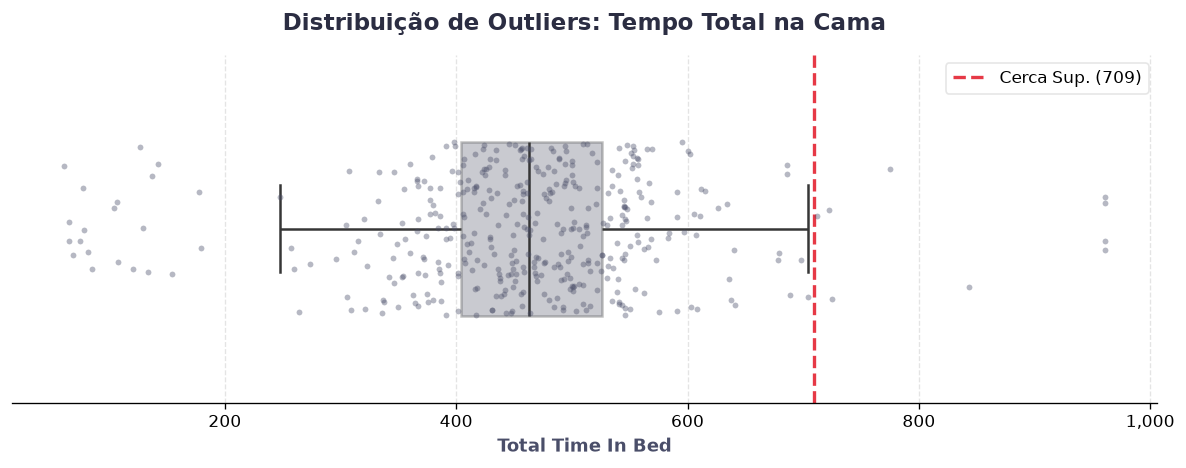

In [621]:
# Gera o Boxplot para inspecionar a distribuição de tempo total na cama
outlier_plot(
    df_plot=dfs['sleep_day'],
    coluna='total_time_in_bed',
    cerca_superior=limite_sup,
    titulo="Distribuição de Outliers: Tempo Total na Cama"
)

#### 8.2.4 Coluna `total_minutes_asleep`

In [622]:
# Calcula os limites para total_minutes_asleep
limite_inf, limite_sup = calculate_limits_iqr(dfs['sleep_day'], 'total_minutes_asleep')

In [623]:
# Executa a função unificada de sumário tabular
outliers_summary(
    df=dfs['sleep_day'],
    coluna='total_minutes_asleep',
    limite_sup=limite_sup,
    limite_inf=limite_inf,
    colunas_analise=dfs['sleep_day'].columns.tolist(),
    titulo="Top 10 maiores registros de Total Minutes Asleep"
)

   RESUMO DE OUTLIERS: TOTAL_MINUTES_ASLEEP 
• Cerca Superior (IQR): 683.50
• Cerca Inferior (IQR): 167.50
• Quantidade de Outliers: 27 de 410 registros
• Impacto na Tabela: 6.59%

• Valor mínimo entre outliers: 58.00
• Valor máximo entre outliers: 796.00

Distribuição de outliers por Utilizador:


,Id_Usuario,dias_com_outlier
0,1644430081,4
1,4558609924,4
2,4388161847,3
3,1927972279,2
4,4319703577,2
5,4445114986,2
6,7007744171,2
7,1503960366,1
8,1844505072,1
9,2320127002,1



Top 10 maiores registros de Total Minutes Asleep:


,user_id,total_minutes_asleep,sleep_date,total_sleep_records,total_time_in_bed,source_folder,minutes_awake_in_bed
27,1644430081,796,2016-05-02,1,961,Fitabase Data 4.12.16-5.12.16,165
246,5553957443,775,2016-04-30,2,843,Fitabase Data 4.12.16-5.12.16,68
32,1927972279,750,2016-04-12,3,775,Fitabase Data 4.12.16-5.12.16,25
30,1844505072,722,2016-04-30,1,961,Fitabase Data 4.12.16-5.12.16,239
4,1503960366,700,2016-04-17,1,712,Fitabase Data 4.12.16-5.12.16,12
125,4319703577,692,2016-04-23,1,722,Fitabase Data 4.12.16-5.12.16,30
36,1927972279,166,2016-04-28,1,178,Fitabase Data 4.12.16-5.12.16,12
89,3977333714,152,2016-04-20,2,305,Fitabase Data 4.12.16-5.12.16,153
28,1644430081,137,2016-05-08,1,154,Fitabase Data 4.12.16-5.12.16,17
195,4558609924,126,2016-04-21,1,137,Fitabase Data 4.12.16-5.12.16,11


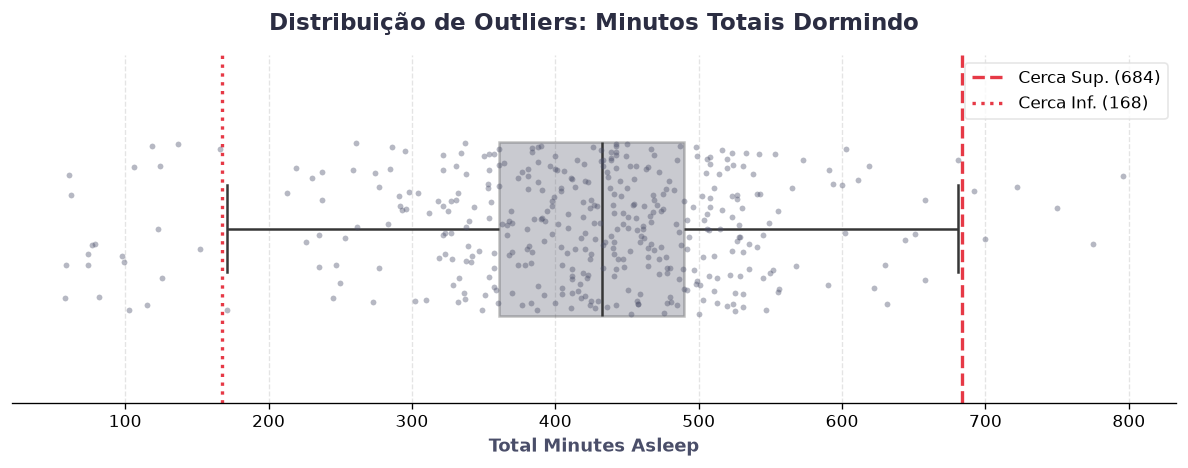

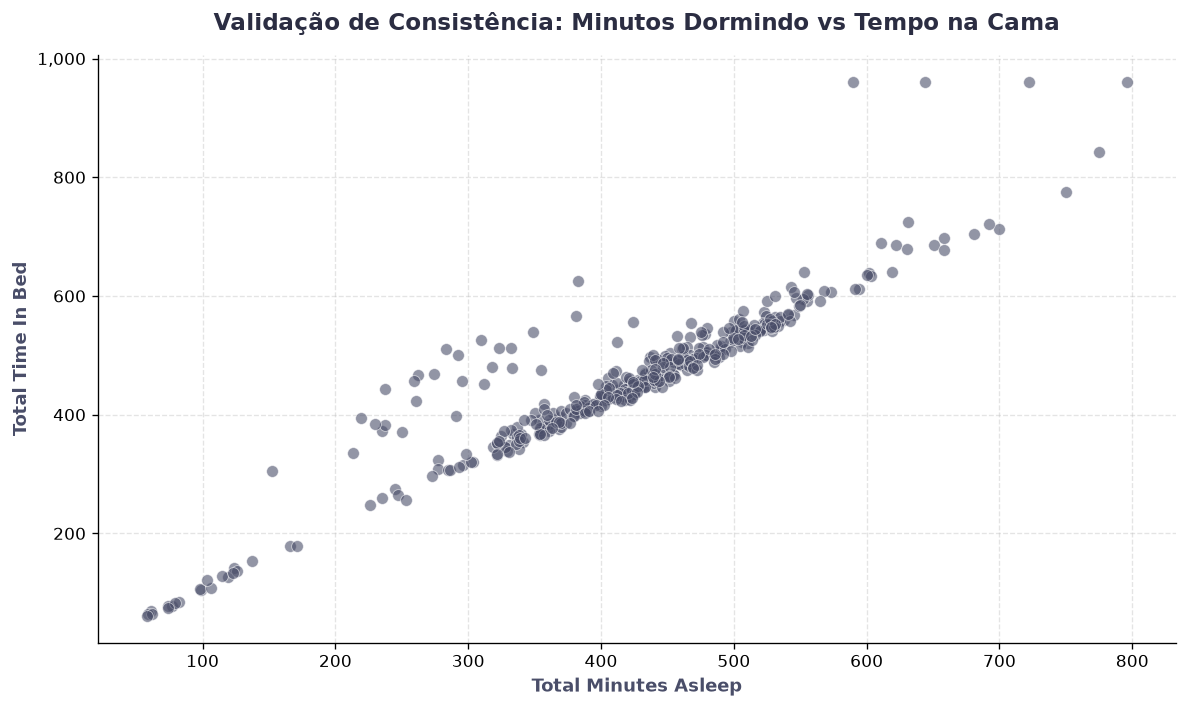

In [624]:
# Boxplot isolado
outlier_plot(
    df_plot=dfs['sleep_day'],
    coluna='total_minutes_asleep',
    cerca_superior=limite_sup,
    cerca_inferior=limite_inf, # Aqui faz sentido olhar a cerca inferior também (pouco sono)
    titulo="Distribuição de Outliers: Minutos Totais Dormindo"
)

# Scatter Plot cruzando tempo dormindo vs tempo na cama
validation_scatter_plot(
    df=dfs['sleep_day'],
    coluna_x='total_minutes_asleep',
    coluna_y='total_time_in_bed',
    titulo="Validação de Consistência: Minutos Dormindo vs Tempo na Cama"
)

#### Validação de Outliers (Tabela `sleep_day`)

#### Comportamento Biológico vs. Erro de Sistema
A análise de valores extremos na tabela de sono confirmou que os desvios estatísticos detetados pelo método IQR representam **comportamento humano legítimo** e não anomalias de hardware ou falhas de registo:
* **`total_minutes_asleep` e `total_time_in_bed`:** Valores muito elevados (mais de 10 a 12 horas) ou residuais refletem variações normais de rotina, como dias de recuperação (fins de semana/doença), sestas isoladas ou episódios reais de insónia.
* **`minutes_awake_in_bed`:** Valores extremos nesta métrica mapeiam hábitos de "higiene do sono" (como ler, ver televisão ou usar o telemóvel deitado). Para o modelo de negócio da Bellabeat, este padrão comportamental é um ativo valioso para gerar recomendações de bem-estar.
* **`total_sleep_records`:** A presença de 2 ou 3 registos no mesmo dia ilustra perfeitamente a divisão de sono em múltiplos blocos (ex: sono noturno somado a uma sesta diurna).

#### Validação Cruzada (*Sanity Check*)
A validação visual cruzando o tempo total a dormir com o tempo total na cama provou uma consistência biológica e matemática rigorosa. A premissa lógica de que *o tempo na cama deve ser sempre igual ou superior ao tempo a dormir* não foi violada nos valores extremos, descartando hipóteses de falhas de processamento do sensor.

#### Decisão de Engenharia (Camada Silver)
**Manutenção integral de 100% dos registos.** Nenhum *outlier* será removido ou transformado, uma vez que a sua exclusão causaria perda de informação crítica sobre os padrões reais de descanso da base de utilizadores e introduziria viés na análise. A tabela está validada e pronta para consumo.

### 8.2 Tabela *hourly_steps*

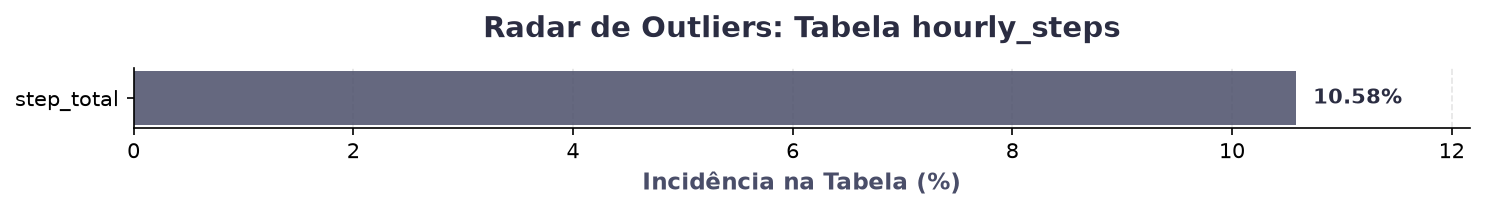

In [625]:
# Executa o diagnóstico em lote
df_diag_hourly_steps = batch_outlier_diagnosis(
    dfs['hourly_steps'], 
    colunas_ignorar=['user_id']
)

# Plota o gráfico resumo
radar_chart_outliers(
    df_diag_hourly_steps,
    titulo="Radar de Outliers: Tabela hourly_steps"
)

In [626]:
# Inspeção rápida do valor máximo absoluto
max_passos_hora = dfs['hourly_steps']['step_total'].max()
print(f"Maior registo de passos numa única hora: {max_passos_hora:,.0f}")

Maior registo de passos numa única hora: 10,565


#### Validação em Lote: Tabela `hourly_steps`
Para a tabela de granularidade horária (`hourly_steps`), aplicou-se a varredura em lote via IQR. Como o comportamento por hora é fortemente cíclico (com blocos de zero durante a madrugada e picos concentrados nos horários de treino/deslocamento), a incidência de *outliers* estatísticos reflete puramente a concentração de atividade física intensa ao longo do dia. 

A inspeção do valor máximo absoluto confirmou a ausência de anomalias de hardware, mantendo-se dentro dos limites fisiológicos humanos de uma caminhada ou corrida intensa. Nenhum registo foi removido, carimbando a base de dados como pronta para a fase de *Merge* e Análise Exploratória (EDA).

### 8.3 Tabela *weight_log'*

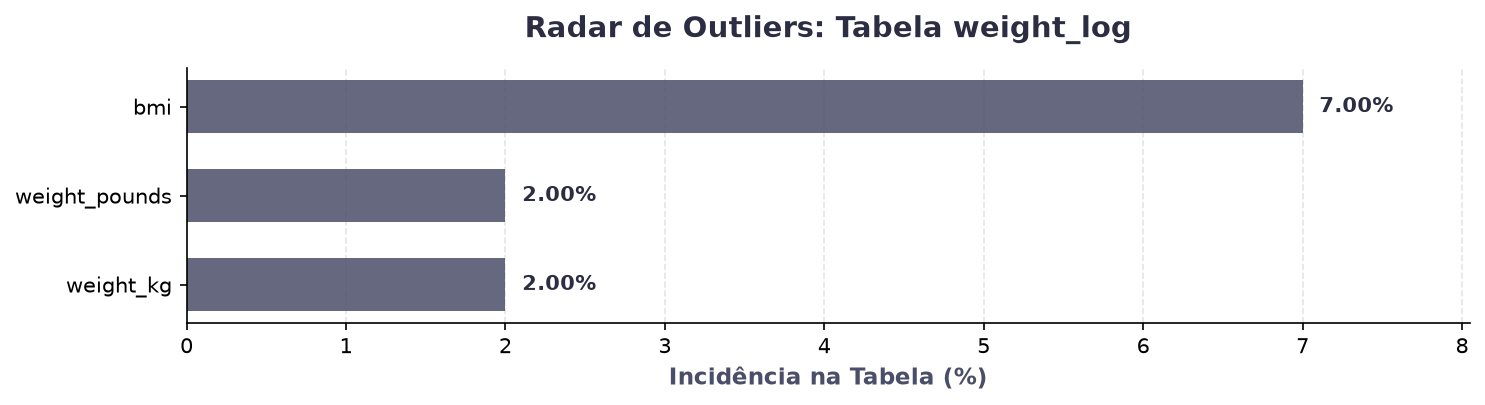

In [627]:
# Executa o diagnóstico em lote
df_diag_weight = batch_outlier_diagnosis(
    dfs['weight_log'], 
    colunas_ignorar=['user_id', 'log_id'] # ignoramos os IDs
)

# Plota o gráfico resumo
radar_chart_outliers(
    df_diag_weight,
    titulo="Radar de Outliers: Tabela weight_log"
)

In [628]:
# Sanity Check: Inspeção rápida de valores extremos
peso_max = dfs['weight_log']['weight_kg'].max()
peso_min = dfs['weight_log']['weight_kg'].min()
bmi_max = dfs['weight_log']['bmi'].max()

print(f"--- Verificação Biológica (Sanity Check) ---")
print(f"Peso mínimo registado: {peso_min:.1f} kg")
print(f"Peso máximo registado: {peso_max:.1f} kg")
print(f"BMI máximo registado: {bmi_max:.1f}")

--- Verificação Biológica (Sanity Check) ---
Peso mínimo registado: 52.6 kg
Peso máximo registado: 133.5 kg
BMI máximo registado: 47.5


#### Validação em Lote: Tabela `weight_log`
A análise de valores extremos na tabela de peso e índice de massa corporal (BMI) exige uma perspetiva fisiológica em vez de puramente estatística. Devido à pequena dimensão da amostra e à variabilidade natural dos biotipos humanos, os desvios sinalizados pelo método IQR representam apenas a diversidade física dos utilizadores monitorizados, e não erros de medição ou falhas no hardware.

O *sanity check* (verificação de consistência) dos limites máximos e mínimos comprovou que todos os registos de `WeightKg` e `BMI` operam dentro de escalas biologicamente possíveis e realistas. Portanto, **nenhum registo foi removido**. 

Com esta etapa concluída, 100% da base de dados está homologada na Camada Silver, pronta para o cruzamento de tabelas (*Merge*) e Análise Exploratória (EDA).